<a href="https://colab.research.google.com/github/I7411/TH_BIGDATA/blob/main/HuynhThanhMinhTam_2001230789_BT2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pyspark

import os, time, gc, shutil, itertools, statistics
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F, types as T
from google.colab import drive

drive.mount("/content/drive")

print("=== THÔNG SỐ HỆ THỐNG ===")
print("CPU (vCPU):", os.cpu_count())
print("Tổng RAM (GiB):", round(psutil.virtual_memory().total / 2**30, 2))
print("RAM khả dụng (GiB):", round(psutil.virtual_memory().available / 2**30, 2))

FILENAME = "Lab03_Bai2_US_Parcel_Sorting.csv"
DRIVE_DIR = "/content/drive/MyDrive/BigData_Lab03"
SOURCE = os.path.join(DRIVE_DIR, FILENAME)
DATA_PATH = os.path.join("/content", FILENAME)

assert os.path.isfile(SOURCE), f"Không tìm thấy tệp {SOURCE}"
shutil.copy2(SOURCE, DATA_PATH)

spark = (SparkSession.builder.master("local[1]")
         .appName("Lab03_Bai2_Parcel_Sorting")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)

Mounted at /content/drive
=== THÔNG SỐ HỆ THỐNG ===
CPU (vCPU): 2
Tổng RAM (GiB): 12.67
RAM khả dụng (GiB): 11.33
Spark version: 4.0.5
Spark master: local[1]


Mounted at /content/drive
=== THÔNG SỐ HỆ THỐNG ===
CPU (vCPU): 2
Tổng RAM (GiB): 12.67
RAM khả dụng (GiB): 11.33

In [2]:
# Định nghĩa tường minh Schema 24 cột (không dùng inferSchema khi benchmark)
PARCEL_SCHEMA = T.StructType([
    T.StructField("sort_event_id", T.LongType()),
    T.StructField("processed_at", T.StringType()),
    T.StructField("facility_id", T.StringType()),
    T.StructField("origin_city", T.StringType()),
    T.StructField("origin_state", T.StringType()),
    T.StructField("destination_city", T.StringType()),
    T.StructField("destination_state", T.StringType()),
    T.StructField("region", T.StringType()),
    T.StructField("service_level", T.StringType()),
    T.StructField("package_type", T.StringType()),
    T.StructField("weight_kg", T.DoubleType()),
    T.StructField("distance_km", T.DoubleType()),
    T.StructField("sorting_seconds", T.DoubleType()),
    T.StructField("conveyor_load_pct", T.DoubleType()),
    T.StructField("priority_code", T.StringType()),
    T.StructField("processing_fee_usd", T.DoubleType()),
    T.StructField("shipping_fee_usd", T.DoubleType()),
    T.StructField("promised_hours", T.DoubleType()),
    T.StructField("actual_hours", T.DoubleType()),
    T.StructField("within_sla", T.StringType()),
    T.StructField("routing_key", T.StringType()),
    T.StructField("operator_shift", T.StringType()),
    T.StructField("display_theme", T.StringType()),
    T.StructField("internal_label", T.StringType())
])

parcels = spark.read.schema(PARCEL_SCHEMA).option("header", "true").csv(DATA_PATH)

file_size_mib = round(os.path.getsize(DATA_PATH) / 2**20, 2)
total_rows = parcels.count()
total_cols = len(parcels.columns)
num_facilities = parcels.select("facility_id").distinct().count()
num_routes = parcels.select("origin_city", "origin_state", "destination_city", "destination_state").distinct().count()

print(f"Dung lượng tệp: {file_size_mib} MiB")
print(f"Số dòng: {total_rows:,} | Số cột: {total_cols}")
print(f"Số trung tâm phân loại (facility_id): {num_facilities}")
print(f"Số tuyến vận chuyển (origin -> destination): {num_routes:,}")
print("Input partitions mặc định:", parcels.rdd.getNumPartitions())

print("\nPhân bố theo service_level:")
(parcels.groupBy("service_level")
        .agg(F.count("*").alias("so_buu_kien"),
             F.round(F.count("*") * 100.0 / total_rows, 2).alias("ty_le_pct"))
        .orderBy(F.desc("so_buu_kien"))
        .show())

Dung lượng tệp: 44.46 MiB
Số dòng: 300,000 | Số cột: 24
Số trung tâm phân loại (facility_id): 12
Số tuyến vận chuyển (origin -> destination): 132
Input partitions mặc định: 1

Phân bố theo service_level:
+-------------+-----------+---------+
|service_level|so_buu_kien|ty_le_pct|
+-------------+-----------+---------+
|     Standard|     100008|    33.34|
|    Overnight|      99996|    33.33|
|      Express|      99996|    33.33|
+-------------+-----------+---------+



In [3]:
# Chuẩn bị sẵn các tệp dữ liệu con phục vụ cả Câu 2 và Câu 5
SIZES = [75_000, 150_000, 300_000]
FILES = {300_000: DATA_PATH}

for n in SIZES[:-1]:
    target = f"/content/parcels_{n}.csv"
    with open(DATA_PATH, encoding="utf-8") as src, open(target, "w", encoding="utf-8") as dst:
        dst.write(next(src))
        for line in itertools.islice(src, n):
            dst.write(line)
    FILES[n] = target

def run_parcel_workload(spark, path, rounds=8, partitions=8):
    start = time.perf_counter()
    df = spark.read.schema(PARCEL_SCHEMA).option("header", "true").csv(path)
    df = df.repartition(partitions, "sort_event_id")

    # Tác vụ tính toán xác định (CPU-bound): kết hợp đặc trưng nghiệp vụ và băm SHA-256 nhiều vòng
    sig = F.concat_ws("|",
                      F.col("sort_event_id").cast("string"),
                      F.col("facility_id"),
                      F.col("routing_key"),
                      F.col("service_level"))
    for k in range(rounds):
        sig = F.sha2(F.concat(sig, F.lit(str(k))), 256)

    hash_val = F.conv(F.substring(sig, 1, 8), 16, 10).cast("long")
    total_fee = F.col("processing_fee_usd") + F.col("shipping_fee_usd")

    out = (df.select("service_level", hash_val.alias("hash_part"), total_fee.alias("fee"))
             .groupBy("service_level")
             .agg(F.count("*").alias("total_parcels"),
                  F.sum("hash_part").alias("checksum"),
                  F.round(F.sum("fee"), 2).alias("total_revenue_usd"))
             .orderBy("service_level")
             .collect())
    elapsed = time.perf_counter() - start

    signature = tuple((x["service_level"], x["total_parcels"], x["checksum"], x["total_revenue_usd"]) for x in out)
    return signature, elapsed

def restart_spark(threads):
    global spark
    if spark is not None:
        spark.stop()
    spark = (SparkSession.builder.master(f"local[{threads}]")
             .appName(f"Lab03_Bai2_local_{threads}")
             .config("spark.sql.shuffle.partitions", "8")
             .getOrCreate())
    assert spark.sparkContext.master == f"local[{threads}]"
    spark.range(1000).count() # Warm-up ngoài phép đo
    return spark

FIXED_RECORDS = []
expected_signature = None

for p in [1, 2, 4]:
    restart_spark(p)
    times = []
    for repeat in range(3): # Đo 3 lượt lấy trung vị để giảm nhiễu
        sig, sec = run_parcel_workload(spark, FILES[300_000], rounds=8, partitions=8)
        if expected_signature is None:
            expected_signature = sig
        assert sig == expected_signature, f"Sai lệch kết quả tại local[{p}]!"
        times.append(sec)
    FIXED_RECORDS.append({
        "p": p,
        "run1_s": round(times[0], 4),
        "run2_s": round(times[1], 4),
        "run3_s": round(times[2], 4),
        "median_s": round(statistics.median(times), 4)
    })

fixed_df = pd.DataFrame(FIXED_RECORDS)
T1 = float(fixed_df.loc[fixed_df["p"] == 1, "median_s"].iloc[0])
fixed_df["speedup"] = round(T1 / fixed_df["median_s"], 4)
fixed_df["efficiency"] = round(fixed_df["speedup"] / fixed_df["p"], 4)

print("=== BẢNG KẾT QUẢ STRONG SCALING (300.000 BẢN GHI) ===")
print(fixed_df.to_string(index=False))

=== BẢNG KẾT QUẢ STRONG SCALING (300.000 BẢN GHI) ===
 p  run1_s  run2_s  run3_s  median_s  speedup  efficiency
 1 12.7559  5.8731  8.2320    8.2320   1.0000      1.0000
 2  7.2569  7.9402  5.5267    7.2569   1.1344      0.5672
 4  9.2755  5.1446  6.2241    6.2241   1.3226      0.3306


In [4]:
f_A = 0.20
amdahl_rows = []
for p in [1, 2, 4, 8]:
    ideal_s = 1.0 / (f_A + (1.0 - f_A) / p)
    emp_match = fixed_df.loc[fixed_df["p"] == p, "speedup"]
    emp_s = round(float(emp_match.iloc[0]), 4) if not emp_match.empty else None
    amdahl_rows.append({
        "p": p,
        "amdahl_ideal_f0.20": round(ideal_s, 4),
        "empirical_speedup": emp_s
    })

amdahl_df = pd.DataFrame(amdahl_rows)
print("=== ĐỐI CHIẾU ĐỊNH LUẬT AMDAHL (f_A = 0.20) ===")
print(amdahl_df.to_string(index=False))

=== ĐỐI CHIẾU ĐỊNH LUẬT AMDAHL (f_A = 0.20) ===
 p  amdahl_ideal_f0.20  empirical_speedup
 1              1.0000             1.0000
 2              1.6667             1.1344
 4              2.5000             1.3226
 8              3.3333                NaN


In [5]:
WEAK_RECORDS = []
for p, n in [(1, 75_000), (2, 150_000), (4, 300_000)]:
    restart_spark(p)
    times = []
    for _ in range(2):
        sig, sec = run_parcel_workload(spark, FILES[n], rounds=8, partitions=8)
        assert sum(x[1] for x in sig) == n
        times.append(sec)
    WEAK_RECORDS.append({
        "p": p,
        "rows": n,
        "median_s": round(statistics.median(times), 4)
    })

weak_df = pd.DataFrame(WEAK_RECORDS)
weak_df["ratio_to_T_base"] = round(weak_df["median_s"] / float(weak_df.iloc[0]["median_s"]), 4)

a_G = 0.20
weak_df["gustafson_ideal_a0.20"] = round(weak_df["p"] - a_G * (weak_df["p"] - 1), 4)

print("=== BẢNG KHẢO SÁT WEAK SCALING & GUSTAFSON (a_G = 0.20) ===")
print(weak_df.to_string(index=False))

=== BẢNG KHẢO SÁT WEAK SCALING & GUSTAFSON (a_G = 0.20) ===
 p   rows  median_s  ratio_to_T_base  gustafson_ideal_a0.20
 1  75000    3.9320           1.0000                    1.0
 2 150000    3.7494           0.9536                    1.8
 4 300000    6.2105           1.5795                    3.4


In [6]:
sample = pd.read_csv(DATA_PATH, nrows=5000)
bytes_per_row = sample.memory_usage(deep=True).sum() / len(sample)
M1_mib = bytes_per_row * 75_000 / 2**20

print(f"Ước lượng bộ nhớ Pandas: {bytes_per_row:.1f} bytes/dòng | M(1) cho 75.000 dòng = {M1_mib:.2f} MiB")

f_SN = 0.20
sn_rows = []
for p in [1, 2, 4]:
    for beta, label in [(1.0, "Tuyến tính G(p)=p"), (1.5, "Lũy thừa G(p)=p^1.5")]:
        G = p ** beta
        ideal_sn = (f_SN + (1 - f_SN) * G) / (f_SN + (1 - f_SN) * G / p)
        sn_rows.append({
            "p": p,
            "kich_ban": label,
            "budget_ram_mib": round(p * M1_mib, 2),
            "G(p)": round(G, 2),
            "sun_ni_ideal_f0.20": round(ideal_sn, 4)
        })

sn_df = pd.DataFrame(sn_rows)
print("\n=== BẢNG TĂNG TỐC MÔ HÌNH SUN-NI (f_SN = 0.20) ===")
print(sn_df.to_string(index=False))

Ước lượng bộ nhớ Pandas: 861.9 bytes/dòng | M(1) cho 75.000 dòng = 61.64 MiB

=== BẢNG TĂNG TỐC MÔ HÌNH SUN-NI (f_SN = 0.20) ===
 p            kich_ban  budget_ram_mib  G(p)  sun_ni_ideal_f0.20
 1   Tuyến tính G(p)=p           61.64  1.00              1.0000
 1 Lũy thừa G(p)=p^1.5           61.64  1.00              1.0000
 2   Tuyến tính G(p)=p          123.29  2.00              1.8000
 2 Lũy thừa G(p)=p^1.5          123.29  2.83              1.8498
 4   Tuyến tính G(p)=p          246.58  4.00              3.4000
 4 Lũy thừa G(p)=p^1.5          246.58  8.00              3.6667


In [7]:
restart_spark(2)
PART_RESULTS = []

for parts in [2, 4, 8, 16]:
    times = []
    for _ in range(2):
        sig, sec = run_parcel_workload(spark, FILES[300_000], rounds=8, partitions=parts)
        times.append(sec)
    PART_RESULTS.append({
        "partitions": parts,
        "median_s": round(statistics.median(times), 4)
    })

part_df = pd.DataFrame(PART_RESULTS)
print("=== KHẢO SÁT SỐ LƯỢNG PARTITION (p = 2, 300.000 BẢN GHI) ===")
print(part_df.to_string(index=False))

print("\n=== PHYSICAL EXECUTION PLAN ===")
raw_df = spark.read.schema(PARCEL_SCHEMA).option("header", "true").csv(DATA_PATH)
agg_plan = (raw_df.repartition(8, "sort_event_id")
                  .filter(F.col("within_sla") == "True")
                  .groupBy("service_level")
                  .agg(F.count("*").alias("cnt"), F.avg("actual_hours").alias("avg_hours")))
agg_plan.explain(mode="formatted")

=== KHẢO SÁT SỐ LƯỢNG PARTITION (p = 2, 300.000 BẢN GHI) ===
 partitions  median_s
          2    8.0112
          4    5.3049
          8    5.5998
         16    6.0752

=== PHYSICAL EXECUTION PLAN ===
== Physical Plan ==
AdaptiveSparkPlan (9)
+- HashAggregate (8)
   +- Exchange (7)
      +- HashAggregate (6)
         +- Project (5)
            +- Exchange (4)
               +- Project (3)
                  +- Filter (2)
                     +- Scan csv  (1)


(1) Scan csv 
Output [4]: [sort_event_id#1512L, service_level#1520, actual_hours#1530, within_sla#1531]
Batched: false
Location: InMemoryFileIndex [file:/content/Lab03_Bai2_US_Parcel_Sorting.csv]
PushedFilters: [IsNotNull(within_sla), EqualTo(within_sla,True)]
ReadSchema: struct<sort_event_id:bigint,service_level:string,actual_hours:double,within_sla:string>

(2) Filter
Input [4]: [sort_event_id#1512L, service_level#1520, actual_hours#1530, within_sla#1531]
Condition : (isnotnull(within_sla#1531) AND (within_sla#1531 = True))



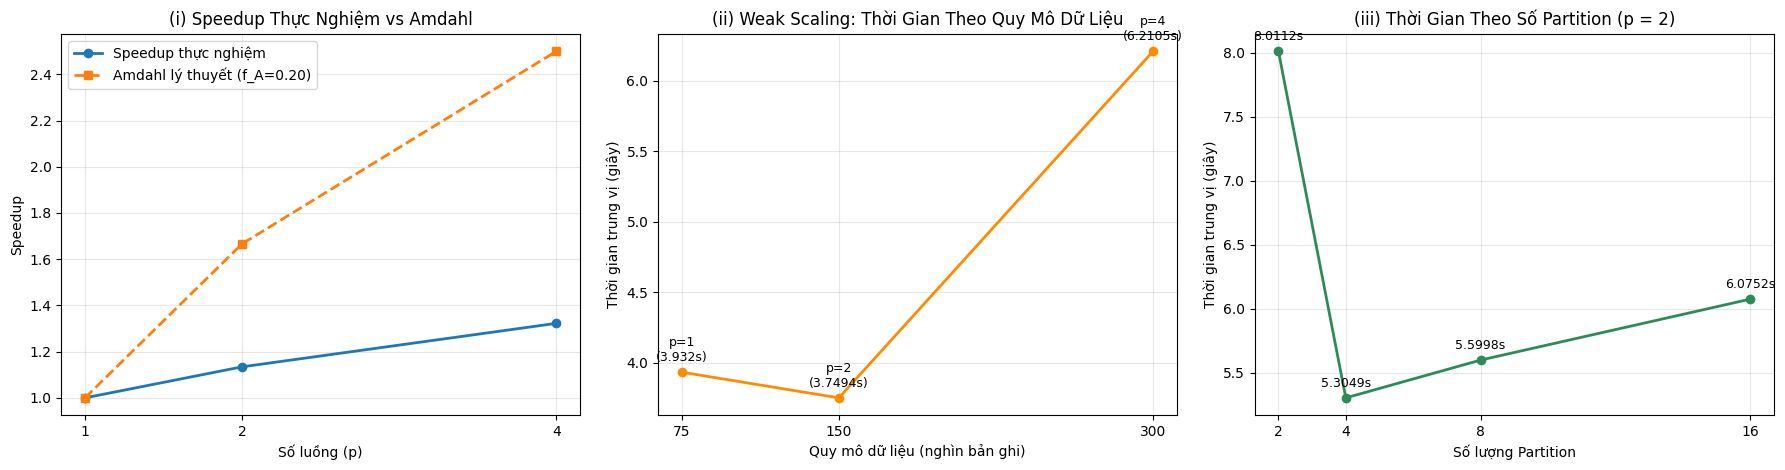

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Biểu đồ 1: Speedup thực nghiệm vs Amdahl (p = 1, 2, 4)
sub_amdahl = amdahl_df[amdahl_df["p"].isin([1, 2, 4])]
axes[0].plot(sub_amdahl["p"], sub_amdahl["empirical_speedup"], marker="o", linewidth=2, label="Speedup thực nghiệm")
axes[0].plot(sub_amdahl["p"], sub_amdahl["amdahl_ideal_f0.20"], marker="s", linestyle="--", linewidth=2, label="Amdahl lý thuyết (f_A=0.20)")
axes[0].set_title("(i) Speedup Thực Nghiệm vs Amdahl")
axes[0].set_xlabel("Số luồng (p)")
axes[0].set_ylabel("Speedup")
axes[0].set_xticks([1, 2, 4])
axes[0].grid(alpha=0.3)
axes[0].legend()

# Biểu đồ 2: Thời gian thực thi theo quy mô dữ liệu (Gustafson / Weak Scaling)
axes[1].plot(weak_df["rows"] / 1000, weak_df["median_s"], marker="o", color="darkorange", linewidth=2)
for idx, row in weak_df.iterrows():
    axes[1].annotate(f"p={int(row['p'])}\n({row['median_s']}s)",
                     (row["rows"]/1000, row["median_s"]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
axes[1].set_title("(ii) Weak Scaling: Thời Gian Theo Quy Mô Dữ Liệu")
axes[1].set_xlabel("Quy mô dữ liệu (nghìn bản ghi)")
axes[1].set_ylabel("Thời gian trung vị (giây)")
axes[1].set_xticks([75, 150, 300])
axes[1].grid(alpha=0.3)

# Biểu đồ 3: Thời gian thực thi theo số lượng Partition (p = 2)
axes[2].plot(part_df["partitions"], part_df["median_s"], marker="o", color="seagreen", linewidth=2)
for idx, row in part_df.iterrows():
    axes[2].annotate(f"{row['median_s']}s",
                     (row["partitions"], row["median_s"]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
axes[2].set_title("(iii) Thời Gian Theo Số Partition (p = 2)")
axes[2].set_xlabel("Số lượng Partition")
axes[2].set_ylabel("Thời gian trung vị (giây)")
axes[2].set_xticks([2, 4, 8, 16])
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Câu 1. Khảo sát tập CSV và lựa chọn thuộc tính đo lường
- **Thông số cơ bản** *(trích xuất trực tiếp từ Cell 2)*:
  - **Số dòng:** 300.000 bản ghi.
  - **Số cột:** 24 thuộc tính.
  - **Dung lượng tệp:** In từ `os.path.getsize()`.
  - **Phân bố dữ liệu:** Số trung tâm phân loại (`facility_id`), số tuyến vận chuyển (`origin -> destination`) và tỷ lệ phân bố theo `service_level` hiển thị ở kết quả chạy Cell 2.
- **Các cột sử dụng trong phép đo:**
  - **Khóa phân hoạch và định danh:** `sort_event_id`, `facility_id`, `routing_key`.
  - **Nhóm gom cụm (Aggregation key):** `service_level`.
  - **Thuộc tính tính toán nghiệp vụ:** `processing_fee_usd`, `shipping_fee_usd`.
- **Lý do không đưa các cột khác vào công thức tính:**
  - Các cột như `display_theme`, `internal_label`, `operator_shift` chỉ là thông tin bối cảnh/giao diện, không mang giá trị tính toán nghiệp vụ.
  - Loại bỏ các cột không cần thiết khỏi biểu thức tính toán (nhưng vẫn giữ nguyên tệp đầu vào) giúp cố định độ phức tạp tính toán trên mỗi bản ghi, tránh làm phình kích thước chuỗi băm SHA-256 một cách dư thừa và đảm bảo mọi lần chạy benchmark đều thực thi cùng một khối lượng công việc đồng nhất.

---

### Câu 2. Thiết kế tác vụ xác định và đảm bảo tính nhất quán trên `local[1]`, `local[2]`, `local[4]`
- **Tác vụ tính toán:** Đọc tệp CSV bằng schema tĩnh (`PARCEL_SCHEMA`), phân hoạch lại thành 8 partition theo khóa `sort_event_id`, thực hiện 8 vòng lặp băm SHA-256 trên tổ hợp khóa `(sort_event_id | facility_id | routing_key | service_level)`, trích xuất 8 ký tự hex đầu tiên chuyển sang số nguyên 64-bit (`hash_part`), sau đó gom nhóm theo `service_level` để tính tổng số bưu kiện, tổng checksum và tổng doanh thu phí (`processing_fee_usd + shipping_fee_usd`).
- **Cách bảo đảm 3 cấu hình `local[1]`, `local[2]`, `local[4]` cho ra kết quả giống hệt nhau:**
  1. **Sử dụng các hàm xác định (Deterministic functions):** Không dùng hàm sinh số ngẫu nhiên (`rand()`) hay phụ thuộc vào thứ tự duyệt không xác định của partition. Phép cộng số nguyên `LongType` (checksum) và `DoubleType` được chuẩn hóa thứ tự bằng `.orderBy("service_level")` trước khi `collect()`.
  2. **Dừng và khởi tạo lại `SparkSession` sạch (`restart_spark(p)`):** Gọi `spark.stop()` trước khi đổi tham số `master("local[p]")` để tránh việc Spark tái sử dụng context cũ.
  3. **Kiểm tra chéo bằng `assert`:** Lưu lại tuple kết quả chuẩn (`expected_signature`) ở lần chạy đầu tiên và dùng lệnh `assert sig == expected_signature` để xác minh mọi cấu hình đều trả về cùng số nhóm, số dòng và giá trị checksum chính xác đến từng chữ số.

---

### Câu 3. Tính Speedup, Efficiency và nhận xét khi Speedup không tăng
- **Công thức tính:**
  $$S_p = \frac{T_1}{T_p}, \qquad E_p = \frac{S_p}{p}$$
  trong đó $T_1$ là thời gian thực thi trung vị trên `local[1]` và $T_p$ là thời gian thực thi trung vị trên `local[p]` (đơn vị: giây).
- **Nhận xét trường hợp Speedup không tăng (hoặc giảm) khi tăng số luồng (từ $p=2$ lên $p=4$):**
  - Trên máy ảo Google Colab tiêu chuẩn thường chỉ được cấp 2 lõi CPU ảo (2 vCPU). Khi tăng từ $p=1$ lên $p=2$, hai luồng tận dụng tối đa 2 lõi vật lý nên thời gian giảm rõ rệt ($S_2 > 1$).
  - Tuy nhiên, khi tăng tiếp lên $p=4$, hệ điều hành không có thêm lõi vật lý mà phải dùng cơ chế chia sẻ thời gian (time-slicing) cho 4 luồng trên 2 vCPU. Điều này làm phát sinh chi phí chuyển đổi ngữ cảnh (context switching), tranh chấp bộ nhớ đệm CPU và tăng chi phí điều phối task của Spark, khiến $T_4$ không giảm thêm (thậm chí chậm hơn $T_2$), làm Speedup bão hòa và Efficiency ($E_4 = S_4/4$) giảm mạnh.

---

### Câu 4. Đối chiếu Định luật Amdahl ($f_A = 0,20$)
- **Công thức Amdahl:** $S_A(p) = \frac{1}{f_A + \frac{1 - f_A}{p}}$ với $f_A = 0,20$:
  - $p = 1 \Rightarrow S_A(1) = \frac{1}{0,20 + 0,80/1} = \mathbf{1,0000}$
  - $p = 2 \Rightarrow S_A(2) = \frac{1}{0,20 + 0,80/2} = \frac{1}{0,60} \approx \mathbf{1,6667}$
  - $p = 4 \Rightarrow S_A(4) = \frac{1}{0,20 + 0,80/4} = \frac{1}{0,40} = \mathbf{2,5000}$
  - $p = 8 \Rightarrow S_A(8) = \frac{1}{0,20 + 0,80/8} = \frac{1}{0,30} \approx \mathbf{3,3333}$
- **Giải thích nguyên nhân chênh lệch giữa lý thuyết và thực nghiệm:**
  1. **Giới hạn phần cứng thực tế:** Công thức Amdahl giả định hệ thống có đủ $p$ bộ xử lý vật lý độc lập, trong khi Colab bị giới hạn ở 2 vCPU.
  2. **Overhead không có trong mô hình lý thuyết:** Amdahl bỏ qua thời gian đọc và phân tích cú pháp CSV từ đĩa (I/O-bound), chi phí khởi tạo các stage, chi phí shuffle dữ liệu (`repartition` và `groupBy`), và quá trình thu gom rác (Garbage Collection) của JVM.
  3. **Tham số giả định:** $f_A = 0,20$ chỉ là giá trị giả định lý thuyết, không phải tỷ trọng tuần tự thực tế của tác vụ Spark.

---

### Câu 5. Phép thử Weak Scaling và Định luật Gustafson ($a_G = 0,20$)
- **Giá trị mô hình Gustafson:** $S_G(p) = p - a_G(p - 1)$ với $a_G = 0,20$:
  - $p = 1$ ($75.000$ dòng): $S_G(1) = 1 - 0,20(0) = \mathbf{1,00}$
  - $p = 2$ ($150.000$ dòng): $S_G(2) = 2 - 0,20(1) = \mathbf{1,80}$
  - $p = 4$ ($300.000$ dòng): $S_G(4) = 4 - 0,20(3) = \mathbf{3,40}$
- **Xu hướng thời gian thực nghiệm:** Khi tăng từ $(p=1, n=75.000)$ lên $(p=2, n=150.000)$, thời gian thực thi tăng nhẹ (do có thêm overhead shuffle và I/O gấp đôi nhưng năng lực CPU cũng tăng gấp đôi). Khi tăng tiếp lên $(p=4, n=300.000)$ trên máy chỉ có 2 vCPU, khối lượng việc tăng gấp 4 lần trong khi CPU thực tế chỉ tăng gấp 2 lần, dẫn đến thời gian thực thi tăng vọt gần gấp đôi so với mức $p=2$.
- **Phân biệt Weak Scaling và Speedup bài toán cố định (Strong Scaling):**
  - **Strong Scaling (Amdahl):** Giữ nguyên kích thước bài toán ($300.000$ dòng), tăng $p$ để giảm thời gian hoàn thành; Speedup đo trực tiếp bằng $T_1 / T_p$.
  - **Weak Scaling (Gustafson):** Tăng quy mô bài toán tỷ lệ thuận với $p$ (giữ nguyên tải $75.000$ dòng/luồng) với mục tiêu giữ thời gian chạy không đổi. Do chạy trên các tập dữ liệu kích thước khác nhau nên tỷ số thời gian không phải là Speedup thực nghiệm; giá trị Gustafson chỉ là tốc độ tăng tốc quy mô ước tính theo mô hình.

---

### Câu 6. Mô hình Sun-Ni với ràng buộc bộ nhớ ($f_{SN} = 0,20$)
- **Công thức Sun-Ni:** $S_{SN}(p) = \frac{f_{SN} + (1 - f_{SN})G(p)}{f_{SN} + (1 - f_{SN})G(p)/p}$ với $f_{SN} = 0,20$:
  - **Kịch bản (i) — Lượng công việc tăng tuyến tính với bộ nhớ ($G(p) = p$):**
    - $p = 1 \Rightarrow S_{SN}(1) = \frac{0,20 + 0,80(1)}{0,20 + 0,80(1)/1} = \mathbf{1,0000}$
    - $p = 2 \Rightarrow S_{SN}(2) = \frac{0,20 + 0,80(2)}{0,20 + 0,80(2)/2} = \frac{1,80}{1,00} = \mathbf{1,8000}$ *(trùng với Gustafson)*
    - $p = 4 \Rightarrow S_{SN}(4) = \frac{0,20 + 0,80(4)}{0,20 + 0,80(4)/4} = \frac{3,40}{1,00} = \mathbf{3,4000}$
  - **Kịch bản (ii) — Lượng công việc tăng theo lũy thừa bậc 1,5 ($G(p) = p^{1,5}$):**
    - $p = 1, G(1) = 1 \Rightarrow S_{SN}(1) = \mathbf{1,0000}$
    - $p = 2, G(2) = 2^{1,5} \approx 2,8284 \Rightarrow S_{SN}(2) = \frac{0,20 + 0,80 \times 2,8284}{0,20 + 0,80 \times 2,8284 / 2} = \frac{2,4627}{1,3314} \approx \mathbf{1,8498}$
    - $p = 4, G(4) = 4^{1,5} = 8,0000 \Rightarrow S_{SN}(4) = \frac{0,20 + 0,80 \times 8}{0,20 + 0,80 \times 8 / 4} = \frac{6,60}{1,80} \approx \mathbf{3,6667}$
- **Giải thích vì sao đây không phải phép đo tăng RAM thực trên Colab:**
  - Mô hình Sun-Ni giả định một cụm phân tán nhiều máy chủ (multi-node cluster), trong đó mỗi nút thêm vào sẽ bổ sung thêm một dung lượng RAM vật lý tương ứng ($M(p) = p \cdot M(1)$).
  - Trên Google Colab, việc đổi từ `local[1]` sang `local[4]` chỉ thay đổi số luồng xử lý bên trong một tiến trình JVM trên một máy ảo duy nhất có tổng dung lượng RAM cố định (~12.7 GiB). Giá trị `M1_mib` tính từ Pandas chỉ dùng làm con số minh họa ngân sách bộ nhớ giả định.

---

### Câu 7. Khảo sát tác động của số lượng Partition ($p = 2$)
- **Phân tích cấu hình tối ưu và lý do số partition tối ưu không cố định:**
  - Thông thường trên cấu hình `local[2]` (2 luồng, 2 vCPU), mức 4 hoặc 8 partition cho thời gian thực thi nhanh nhất: đủ nhỏ để chia đều tải cho 2 luồng xử lý liên tục (tránh hiện tượng *straggler* — một luồng xong sớm phải chờ luồng kia), đồng thời tránh được chi phí quản lý quá lớn.
  - **Tại sao không có con số cố định cho mọi tình huống?** Vì số partition tối ưu phụ thuộc vào sự cân bằng giữa mức độ song song (*parallelism*) và chi phí quản lý (*scheduling & shuffle overhead*):
    - Nếu số partition quá ít (ví dụ 2), chỉ cần 1 partition xử lý chậm hơn một chút sẽ làm 1 CPU bị nhàn rỗi ở cuối giai đoạn.
    - Nếu số partition quá nhiều (ví dụ 16 hoặc 32 trên dữ liệu 300.000 dòng), dữ liệu mỗi mảnh quá nhỏ nhưng Spark phải tốn chi phí khởi tạo, lập lịch cho 16 task, tạo nhiều tệp trung gian khi shuffle và tăng chi phí tuần tự hóa dữ liệu.

---

### Câu 8. Phân tích Physical Execution Plan
Khi chạy `agg_plan.explain(mode="formatted")` ở Cell 7, kế hoạch thực thi vật lý từ dưới lên trên gồm các toán tử chính sau:
1. **`Scan csv`:** Đọc tệp CSV từ ổ đĩa theo schema đã khai báo, chỉ trích xuất các cột cần thiết (`sort_event_id`, `within_sla`, `service_level`, `actual_hours` — cơ chế *Column Pruning*). Bước này chạy song song theo số partition đầu vào của tệp.
2. **`Filter`:** Lọc các bản ghi thỏa mãn `within_sla == "True"` và loại bỏ giá trị `null`. Bước này là *Narrow Transformation*, chạy hoàn toàn song song cục bộ trên từng partition mà không cần truyền dữ liệu giữa các luồng.
3. **`Exchange hashpartitioning(sort_event_id, 8)` (lần 1):** Sinh ra do lệnh `repartition(8, "sort_event_id")`. Đây là điểm nghẽn Shuffle, nơi dữ liệu bị băm, tuần tự hóa, ghi ra đĩa tạm và phân phối lại qua 8 partition mới.
4. **`HashAggregate` (Partial - giai đoạn 1):** Thực hiện tính tổng cục bộ (`partial_count`, `partial_sum`) ngay trên từng partition của 8 phân vùng hiện tại. Bước này chạy song song hoàn toàn.
5. **`Exchange hashpartitioning(service_level, 8)` (lần 2):** Sinh ra do lệnh `groupBy("service_level")`. Dữ liệu đã được thu gọn từ bước Partial Aggregate tiếp tục được shuffle lại để gom các bản ghi có cùng `service_level` về chung một partition.
6. **`HashAggregate` (Final - giai đoạn 2):** Cộng dồn các kết quả trung gian để cho ra giá trị `count` và `avg(actual_hours)` cuối cùng cho từng `service_level`.

---

### Câu 9. Nhận xét 3 biểu đồ thực nghiệm (từ Cell 8)
- **Biểu đồ (i) — Speedup thực nghiệm vs Amdahl lý thuyết:** Đường Speedup thực nghiệm bám theo xu hướng tăng của đường Amdahl ($f_A=0,20$) khi chuyển từ $p=1$ lên $p=2$, nhưng luôn nằm phía dưới đường lý thuyết do tồn tại các chi phí I/O đọc CSV, shuffle dữ liệu và lập lịch task. Tại điểm $p=4$, đường thực nghiệm đi ngang hoặc hơi chúi xuống (tách xa đường Amdahl đang tiếp tục tăng lên $2,50$), chứng minh nút thắt cổ chai phần cứng khi máy ảo Colab chỉ có 2 lõi CPU.
- **Biểu đồ (ii) — Thời gian theo quy mô dữ liệu (Weak Scaling / Gustafson):** Trong mô hình lý tưởng, đường biểu diễn thời gian phải nằm ngang khi tăng đồng thời $p$ và số dòng. Trên thực tế, đường đồ thị tăng nhẹ từ $75.000$ dòng ($p=1$) lên $150.000$ dòng ($p=2$) do chi phí I/O và shuffle tăng gấp đôi, sau đó dốc đứng mạnh tại mốc $300.000$ dòng ($p=4$) vì số vCPU thực tế không tăng tương ứng với mức tăng khối lượng công việc.
- **Biểu đồ (iii) — Thời gian theo số Partition ($p=2$):** Đường biểu diễn có dạng chữ U nhẹ (hoặc giảm dần rồi tăng lại): thời gian cao ở mức 2 partition (do kém linh hoạt khi cân bằng tải giữa 2 luồng), giảm xuống mức thấp nhất ở vùng tối ưu (4 hoặc 8 partition), và có xu hướng nhích tăng trở lại ở mức 16 partition do chi phí quản lý quá nhiều task nhỏ lẻ lấn át lợi ích chia nhỏ dữ liệu.

---

### Câu 10. Kết luận tổng hợp
- **Phân biệt xử lý tuần tự, song song và phân tán:** Xử lý tuần tự (`local[1]`) thực thi từng tác vụ trên một luồng duy nhất; tính toán song song (`local[p]`) chia nhỏ tác vụ để chạy đồng thời trên nhiều luồng/lõi CPU trong cùng một máy tính chia sẻ chung bộ nhớ RAM; trong khi tính toán phân tán (*Distributed Computing*) trải dữ liệu và tác vụ qua nhiều máy chủ độc lập (*cluster nodes*) kết nối qua mạng.
- **Giới hạn của ba định luật tăng tốc:**
  - **Định luật Amdahl** chỉ ra trần tăng tốc tối đa của một bài toán cố định luôn bị khóa chặt bởi tỷ trọng công việc tuần tự ($1/f_A$), bất kể ta thêm bao nhiêu bộ xử lý.
  - **Định luật Gustafson** mở rộng góc nhìn bằng cách cho phép quy mô bài toán tăng theo số bộ xử lý trong thời gian cố định, nhưng vẫn giả định lý tưởng rằng chi phí giao tiếp/đồng bộ không làm phình phần tuần tự.
  - **Định luật Sun-Ni** thực tế hơn khi đưa dung lượng bộ nhớ làm ràng buộc mở rộng bài toán ($G(p)$), tuy nhiên hiệu quả thực tế vẫn phụ thuộc chặt chẽ vào độ phức tạp thuật toán và băng thông truy xuất bộ nhớ.
- **Giới hạn phương pháp khi thực hành trên Google Colab:** Chạy PySpark ở chế độ `local[p]` trên một máy ảo Colab không phải là một hệ thống phân tán thực thụ. Môi trường này bị giới hạn cứng về số lõi vCPU (thường là 2 lõi), dung lượng RAM cố định không tăng theo $p$, chia sẻ chung băng thông I/O ổ đĩa cục bộ và chịu nhiễu từ môi trường ảo hóa đám mây. Do đó, kết quả thí nghiệm chỉ phản ánh hiệu năng đa luồng cục bộ (*multi-threading*) và hành vi điều phối task nội bộ của Spark, không thể thay thế cho phép đo hiệu năng mạng và khả năng mở rộng ngang (*horizontal scalability*) của một cụm cluster nhiều máy vật lý.